In [21]:
from pathlib import Path
import cv2 as cv2
import numpy as np
import matplotlib.pyplot as plt


OUT_DIR = Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)  # creates outputs/ if it doesn't exist
print("Saving to:", OUT_DIR.resolve())

Saving to: /Users/aaronbaggot/Desktop/Image_Processing_Assignment_1/outputs


In [22]:
# Load image
img_path = Path("data/raw/Shark 1.PNG")
I = cv2.imread(str(img_path), cv2.IMREAD_COLOR)
if I is None:
    raise exception(f"Image not found: {img_path}")

h, w = I.shape[:2] # Only need h and w chanel count can vary(3 for BGR, 1 for grey




In [23]:
# Resize the image

S = cv2.resize(I, dsize=(2 * w, 2 * h), interpolation=cv2.INTER_CUBIC)

# Crop a section (top left 180x270) indices are [y1:y2, x1:x2]
C = I[0:min(180, h), 0:min(270, w)]

# Get the image center for rotation
cx, cy = w // 2, h // 2

# Rotate parameters
angle = 45
scale = 1.0

# Rotation matrix and apply rotation on the same canvas size
M = cv2.getRotationMatrix2D(center=(cx, cy), angle=angle, scale=scale)


# Use BORDER_REFLECT to avoid black corners on the edges
R = cv2.warpAffine(I, M, dsize=(w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)


(np.float64(-0.5), np.float64(1019.5), np.float64(681.5), np.float64(-0.5))

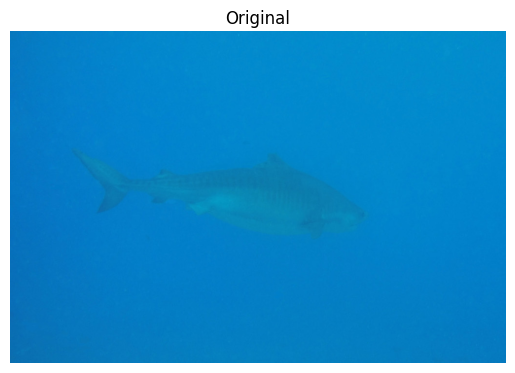

In [24]:
plt.imshow(cv2.cvtColor(I, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")



(np.float64(-0.5), np.float64(2039.5), np.float64(1363.5), np.float64(-0.5))

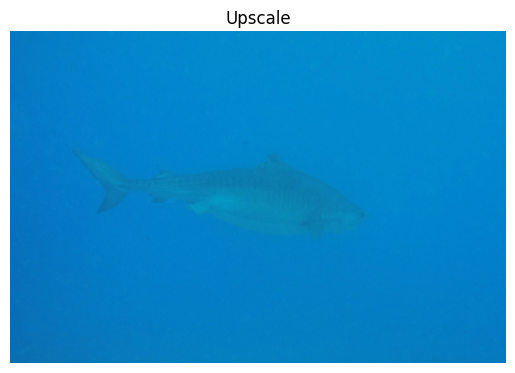

In [25]:
plt.imshow(cv2.cvtColor(S, cv2.COLOR_BGR2RGB))
plt.title("Upscale")
plt.axis("off")

(np.float64(-0.5), np.float64(269.5), np.float64(179.5), np.float64(-0.5))

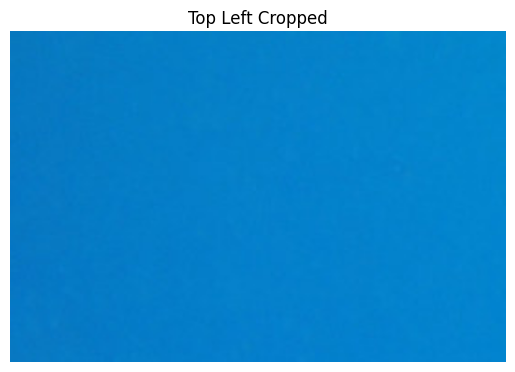

In [26]:
plt.imshow(cv2.cvtColor(C, cv2.COLOR_BGR2RGB))
plt.title("Top Left Cropped")
plt.axis("off")

(np.float64(-0.5), np.float64(1019.5), np.float64(681.5), np.float64(-0.5))

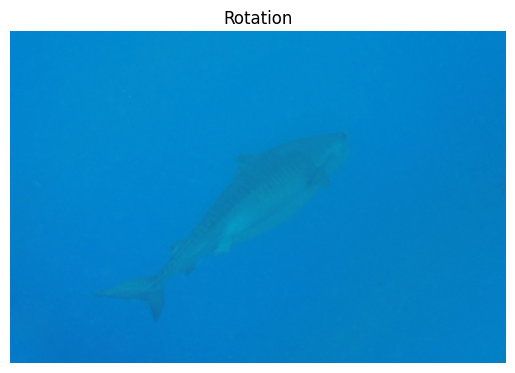

In [27]:
plt.imshow(cv2.cvtColor(R, cv2.COLOR_BGR2RGB))
plt.title("Rotation")
plt.axis("off")

In [28]:
cv.imwrite(str(OUT_DIR / "01_original.png"), I)
cv.imwrite(str(OUT_DIR / "02_upscaled.png"), S)
cv.imwrite(str(OUT_DIR / "03_crop.png"), C)
cv.imwrite(str(OUT_DIR / "04_rotated.png"), R)

print("Saved basic outputs.")

NameError: name 'cv' is not defined